## Lecture 3 — Clutter is Your Enemy + Line Charts


> **Dataset:** CO2 Emissions by Country 2000-2022 [Our World in Data](https://ourworldindata.org/co2-emissions)

> **Source of figures:** Knaflic, C. N. (2015). *Storytelling with data*. Wiley.



---
## Opening: Model Answer Review 


## Design Principles - Part I: Remove Clutter


### Cognitive load

> 💡 **Every element you add to a chart requires the viewer's brain to process it. This is cognitive load. Clutter is anything that consumes that brain power without adding information. Every non-data element is a candidate for removal**


*Original ticket volume chart — the cluttered 'before' used in  Lecture 2 [ FIGURE 3.17 — p.91 ]*

> 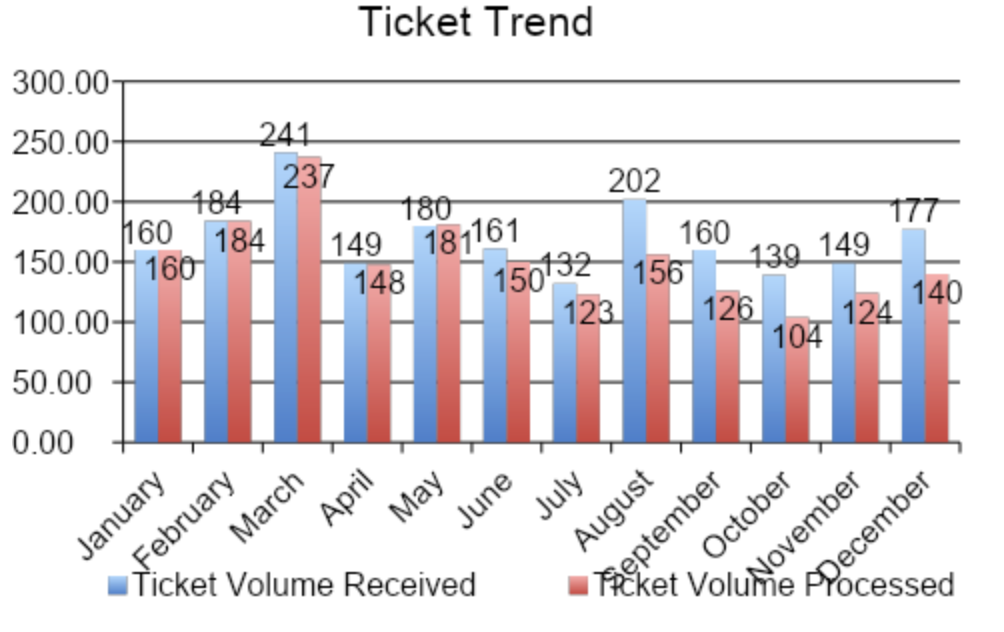 



### 💡 The 6️⃣ Gestalt principles

- Gestalt principles are a set of rules describing how the human visual system organises elements into perceived wholes

- Developed in the early 20th century by a group of German psychologists Max Wertheimer, Kurt Koffka, Wolfgang Köhler — working within the Gestalt school of psychology

- The word Gestalt is German for "form" or "shape"


**1. Proximity: elements placed close together are perceived as belonging to the same group**

> 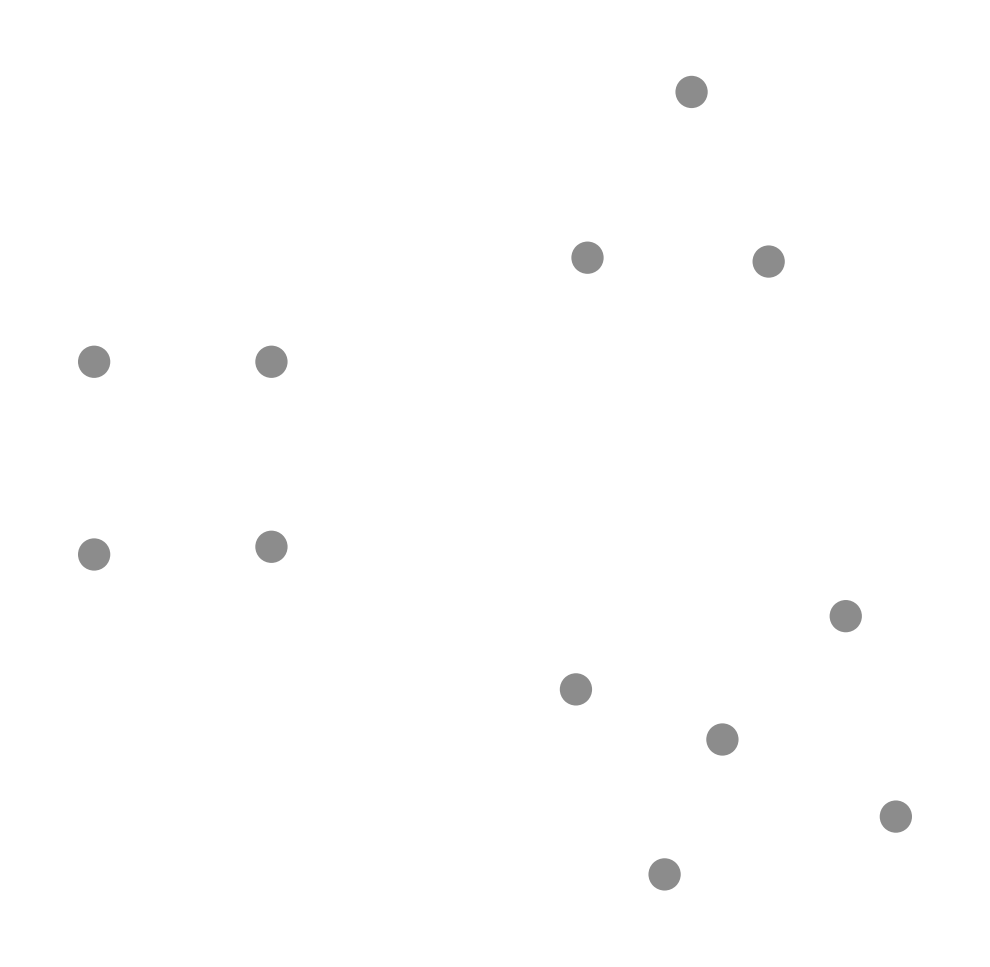

> 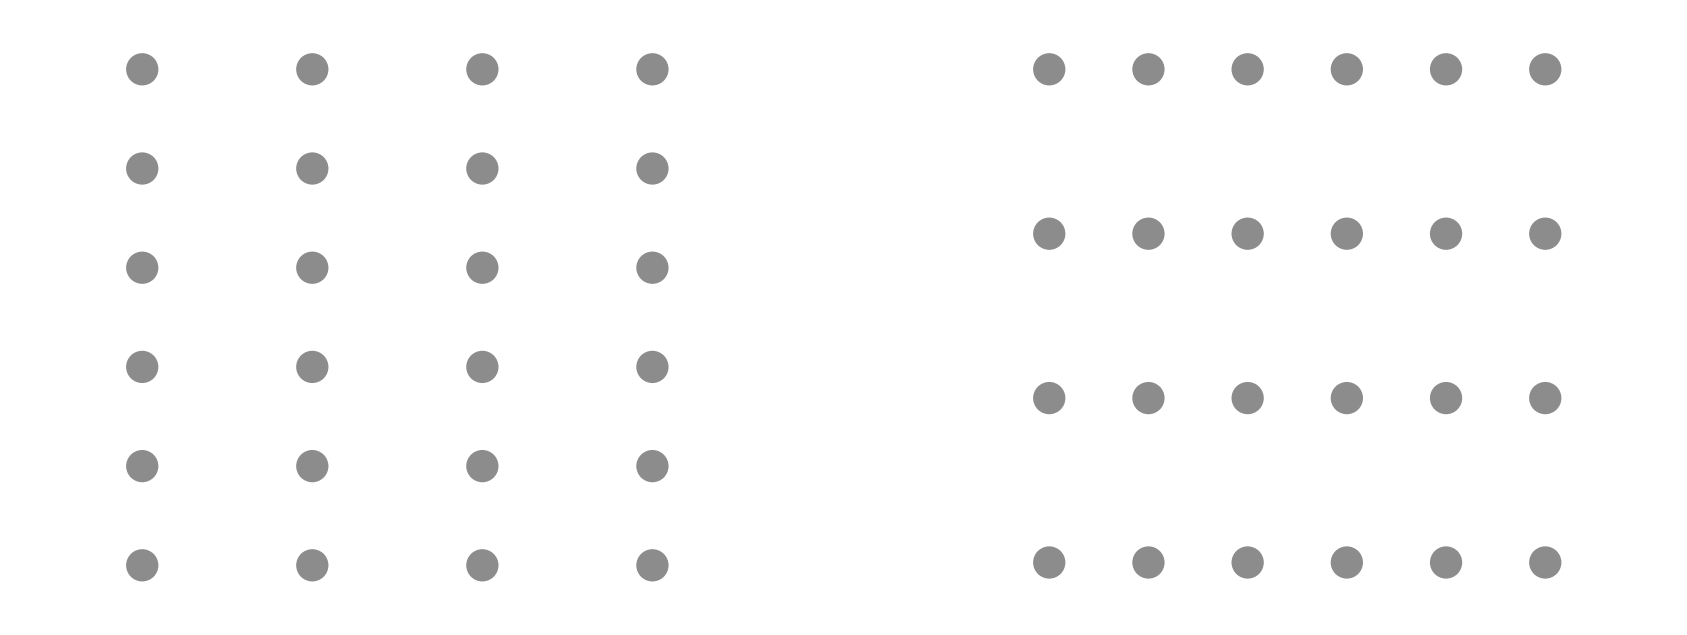 


**2. Similarity: elements that share colour, shape, or size are perceived as related**

> 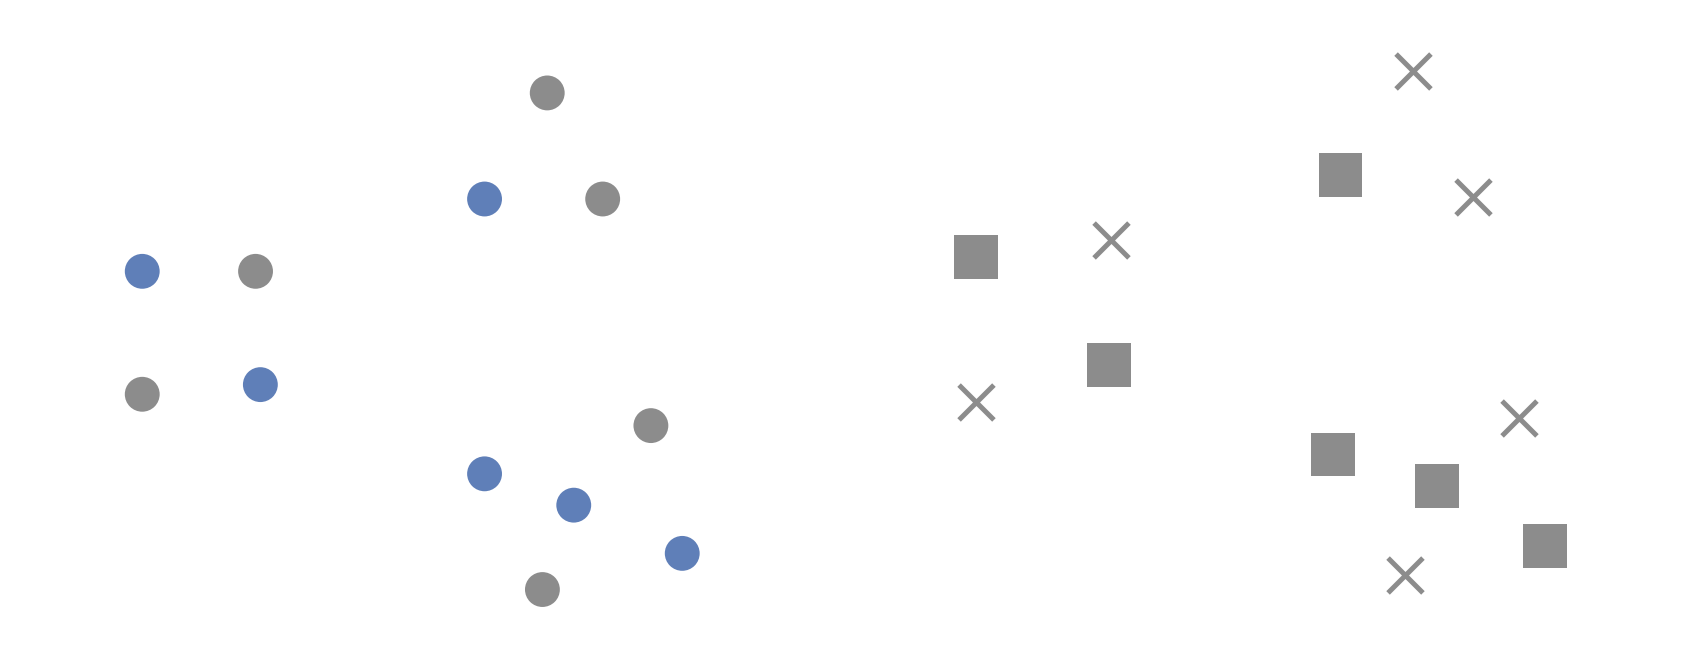 

> 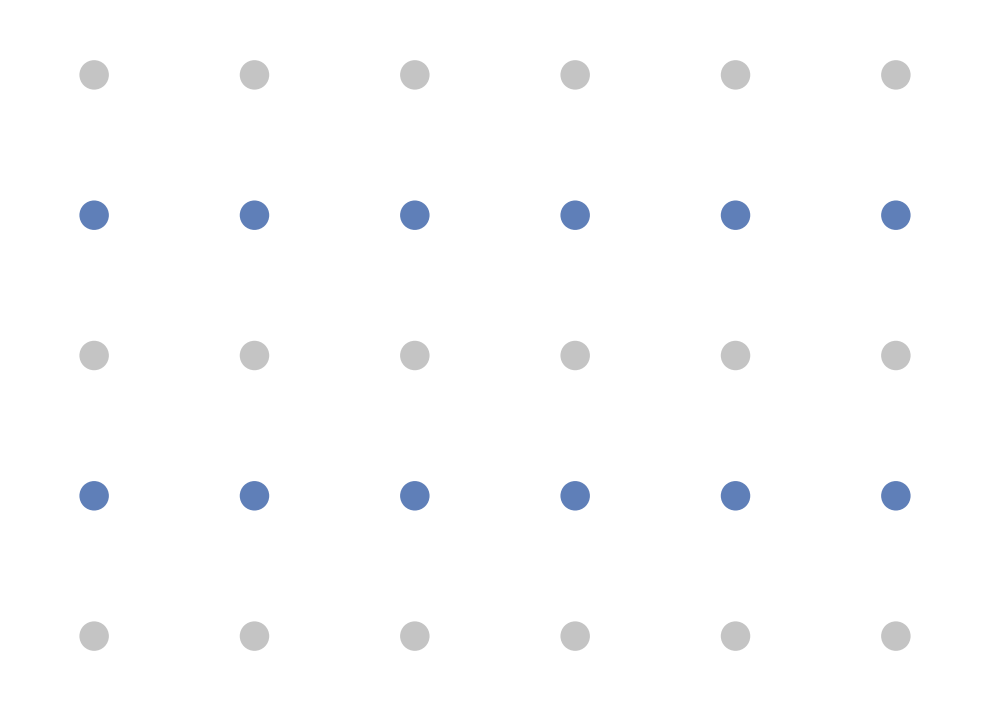 



**3. Enclosure: elements within a shared boundary or shaded region are perceived as a group**

> 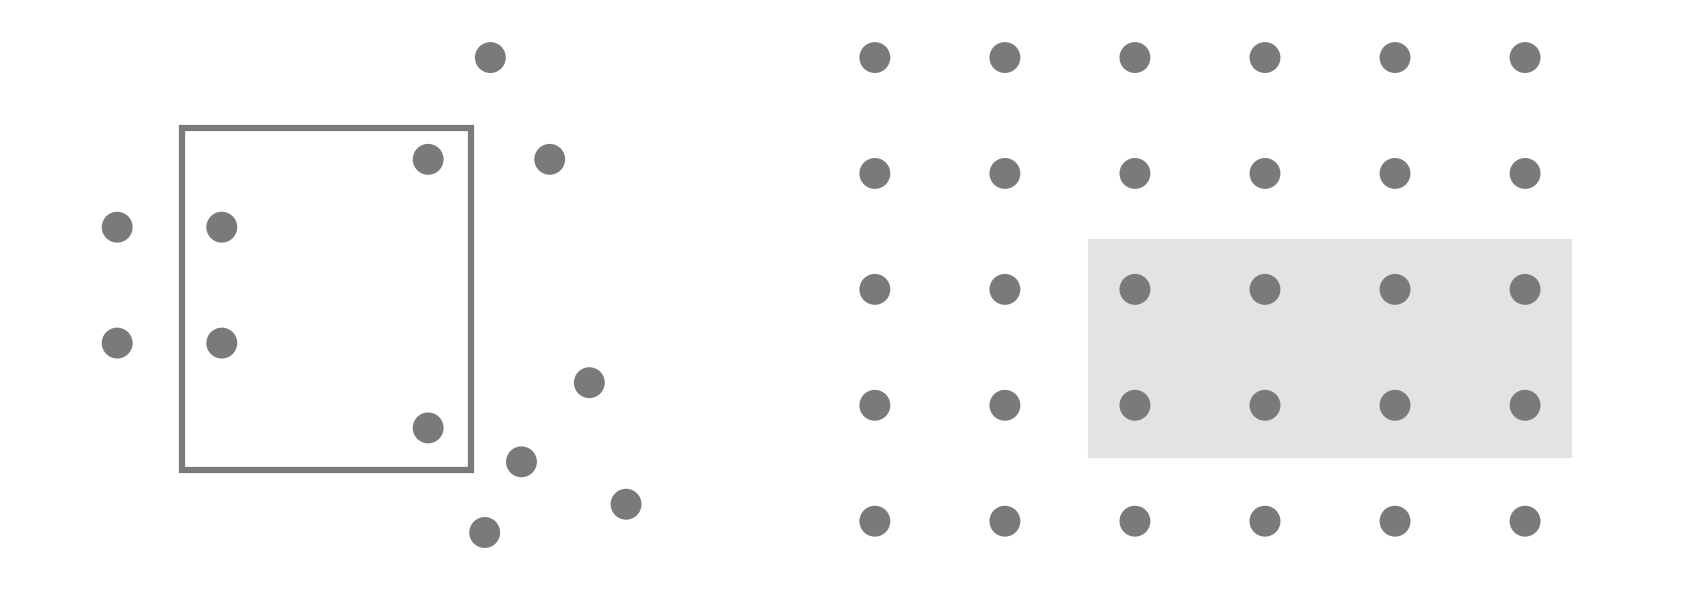

> 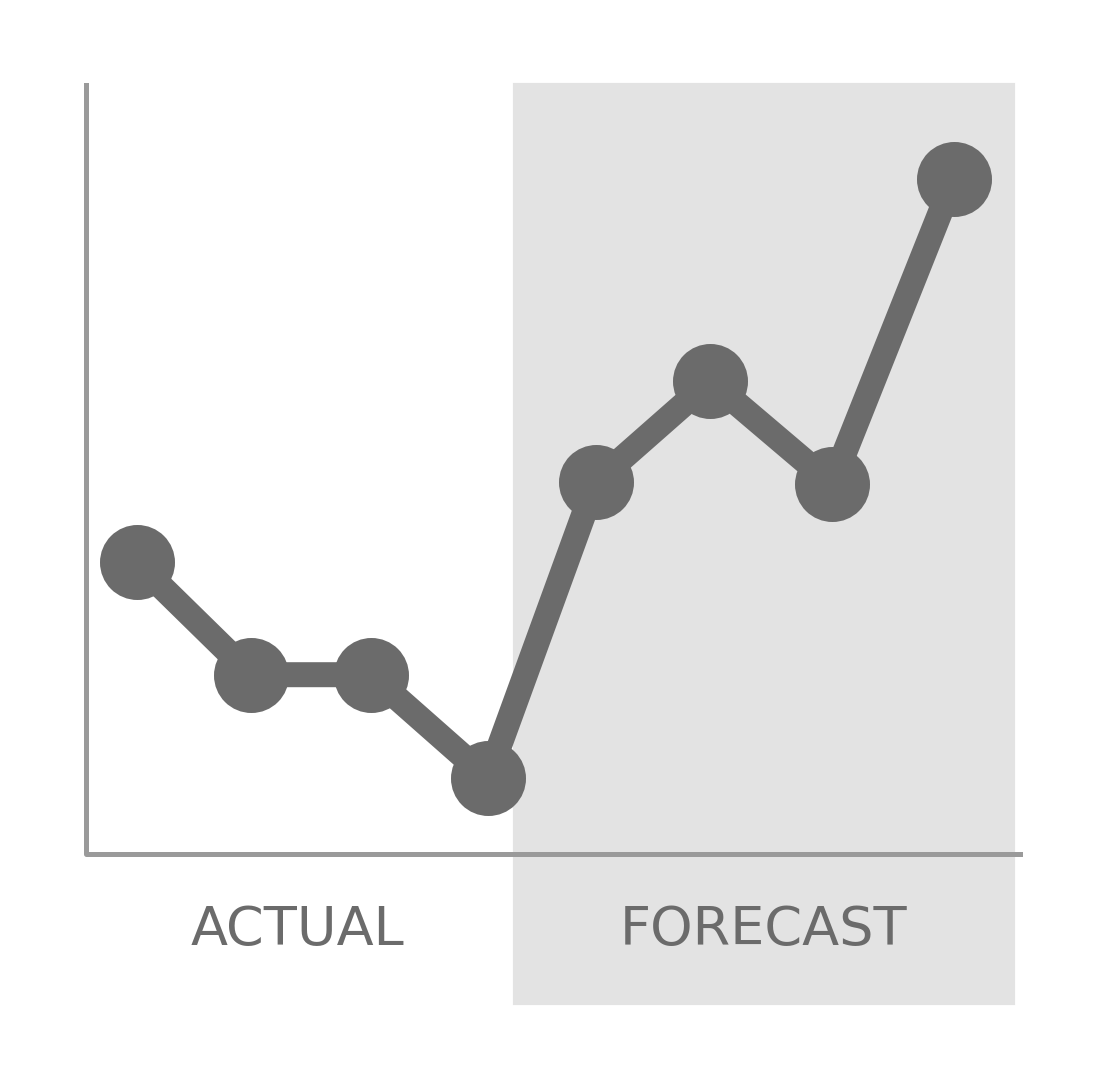



**4. Closure: the mind automatically completes incomplete shapes; full borders are rarely needed**

> 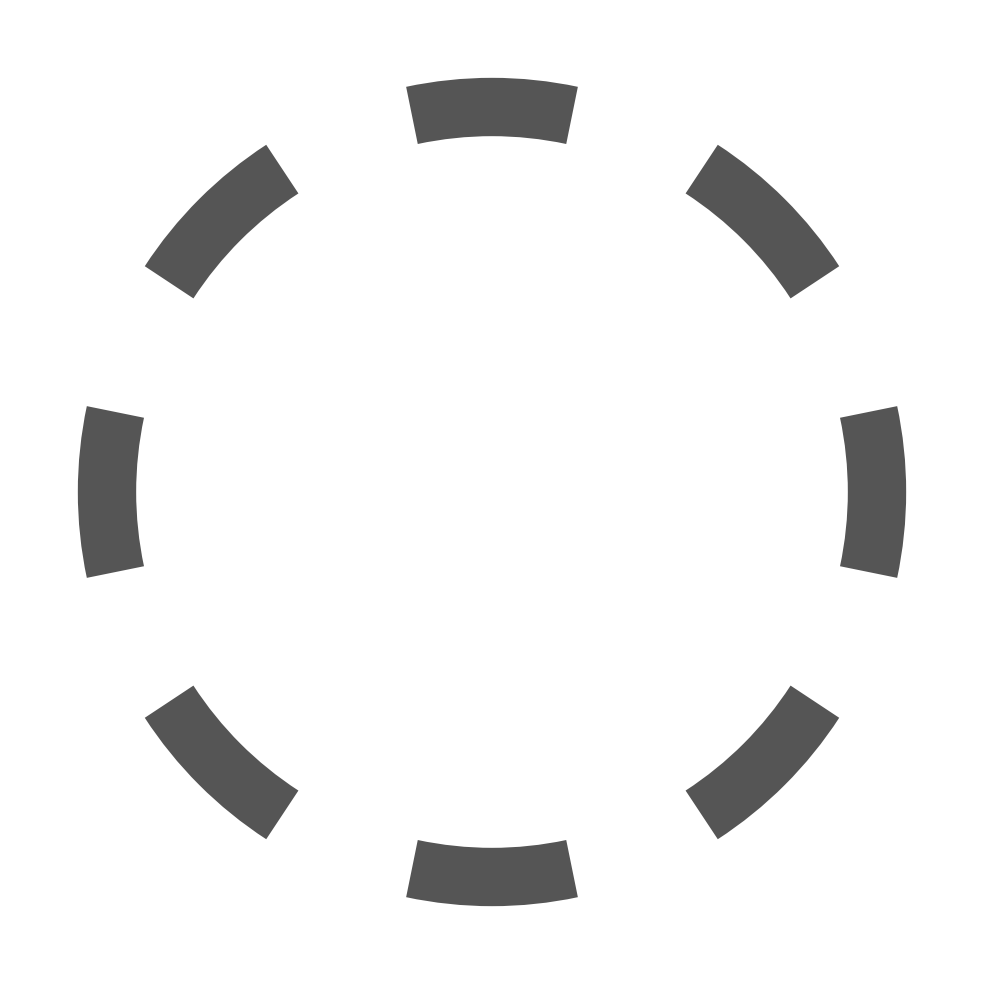 

> 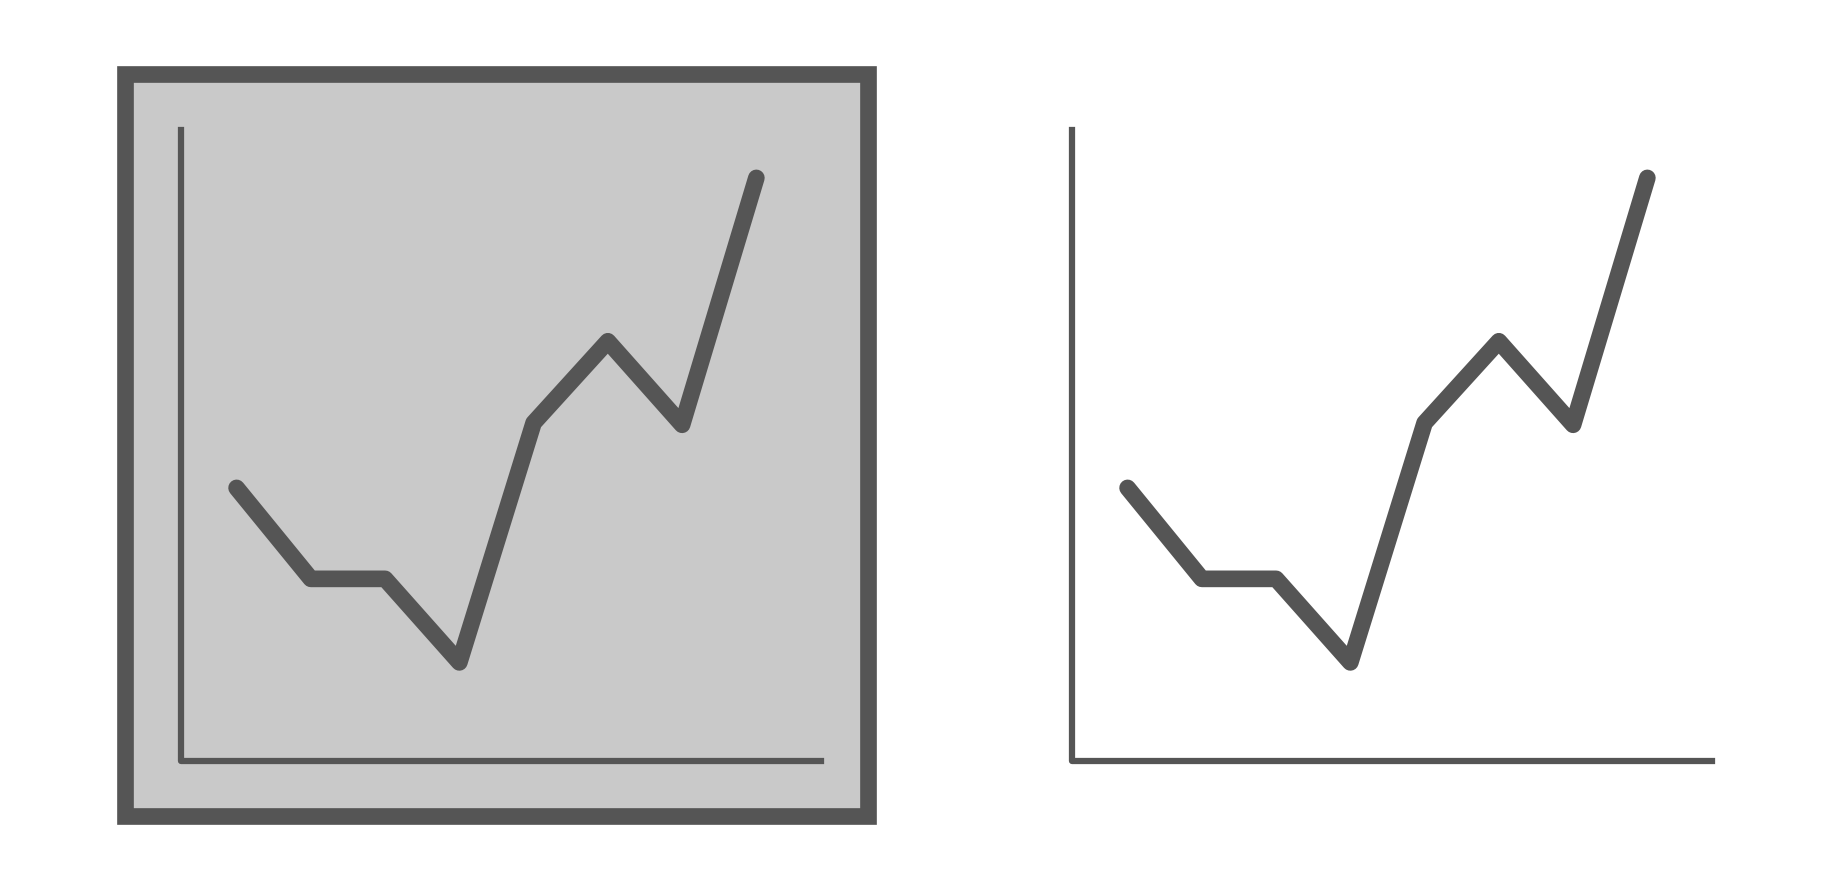 


**5.Continuity: the eye follows the smoothest path and naturally create continuity in what we see even where it may not explicitly exist, so gridlines and axis lines often add more friction than value**

> 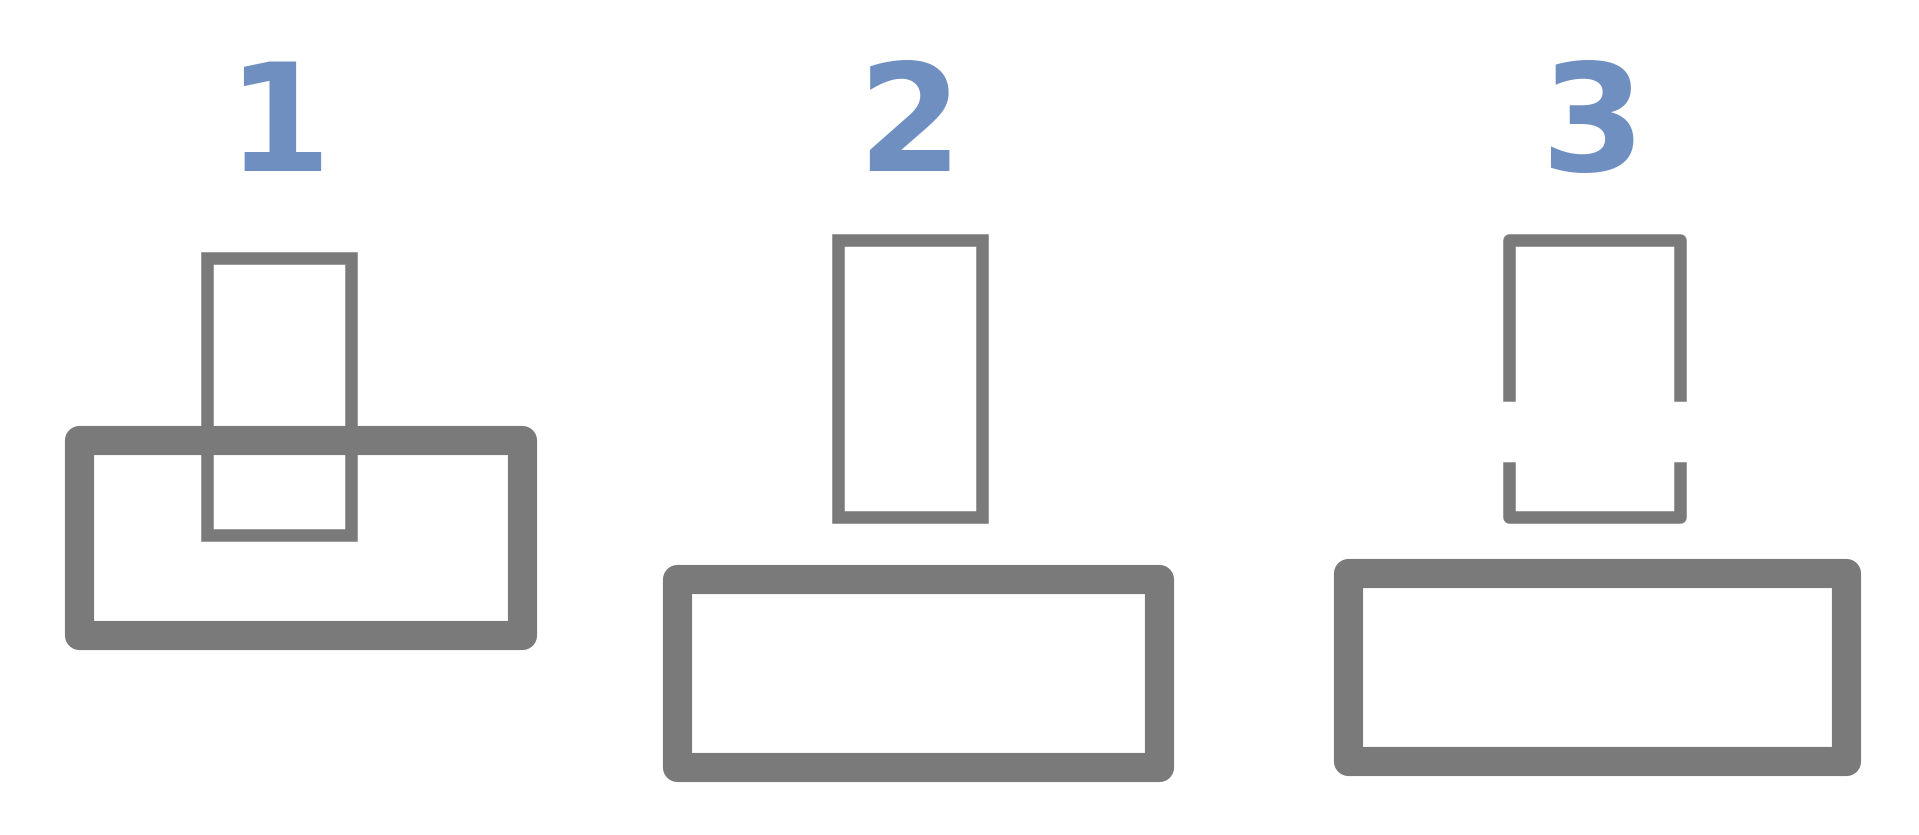 

> 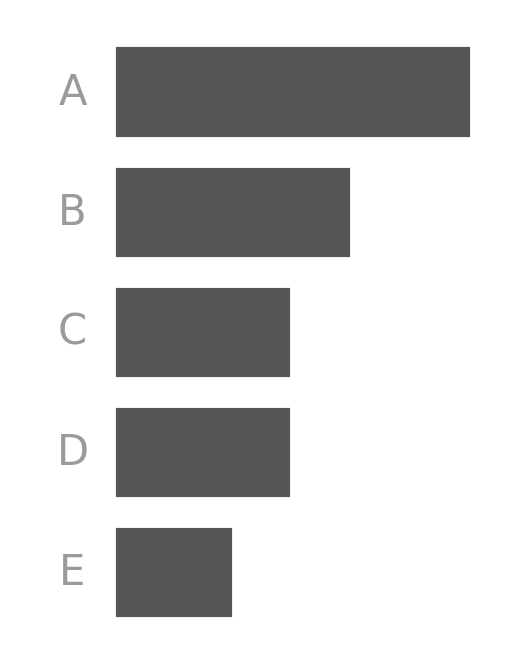 



**6. Connection: elements joined by a line are seen as related, making it the strongest grouping cue of all — overrides proximity and similarity**

> 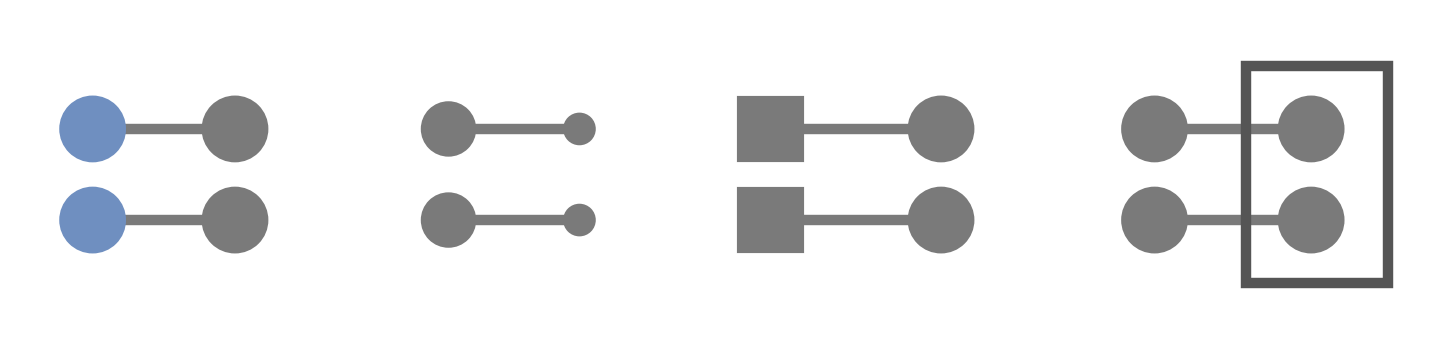 

> 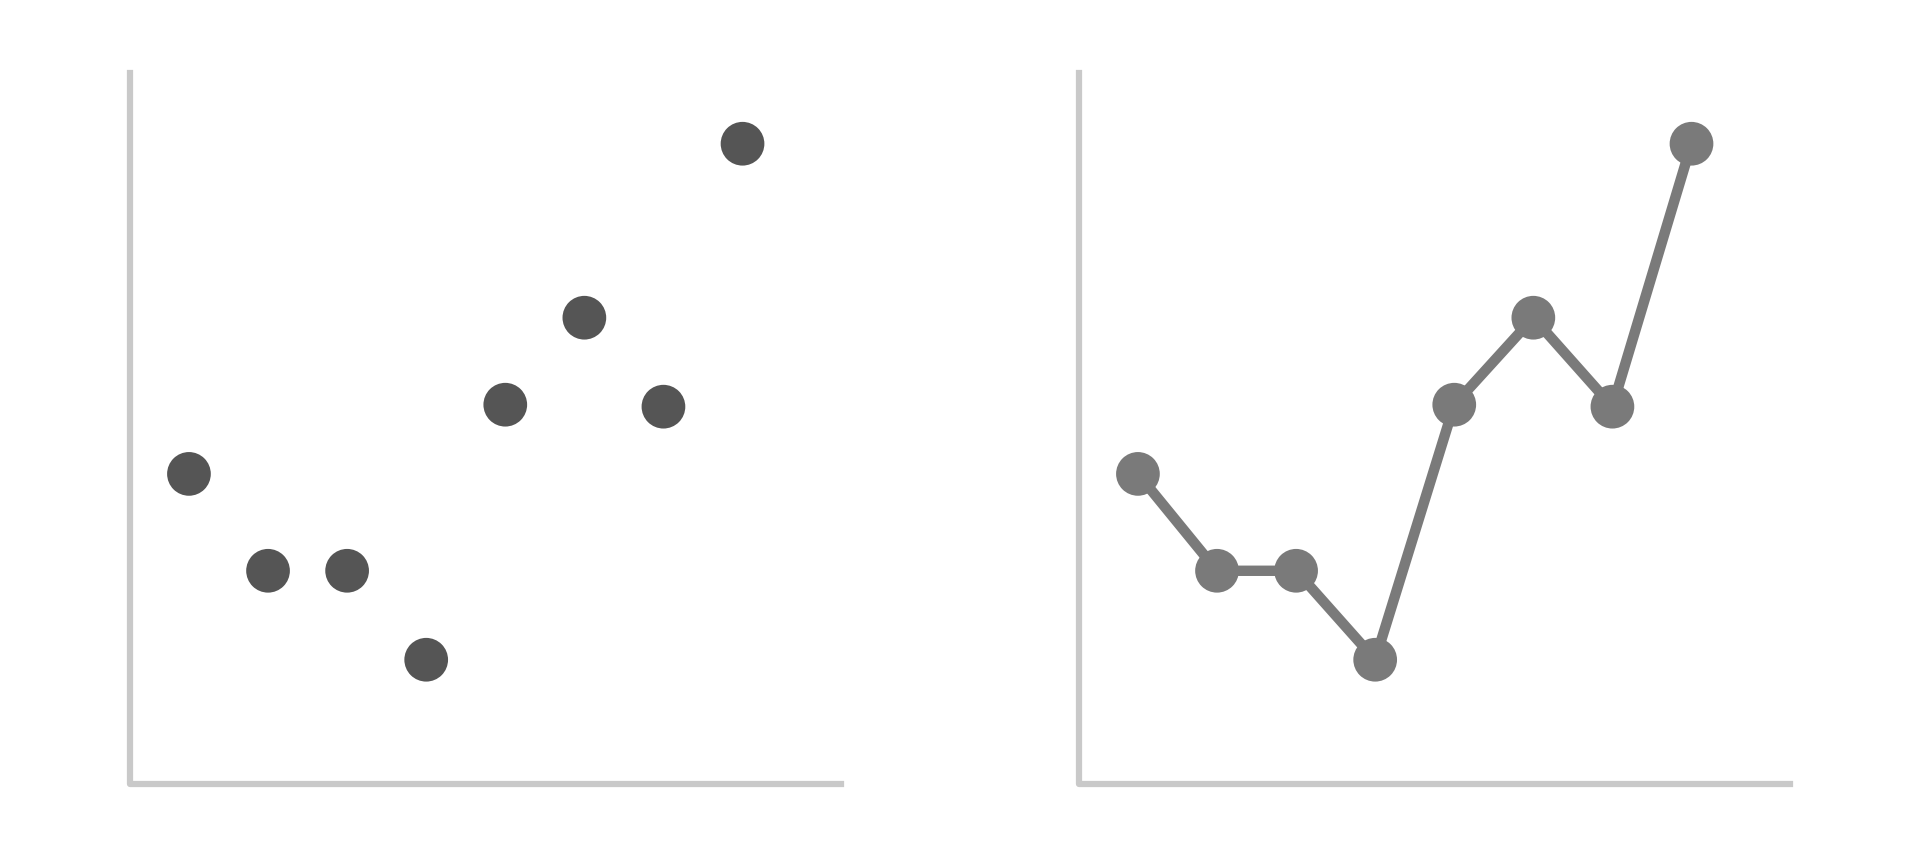 



**Practical hit list — elements to remove by default:**

| Remove | Why |
|---|---|
| Chart border | Gestalt closure — the eye sees the chart edge without it |
| Gridlines (or lighten to #EEEEEE) | Data should stand out, not the grid |
| Data markers on every point | Adds cognitive load with no new information |
| Legend when you can label directly | Legend forces eye movement; labels use proximity |
| Trailing zeros (0.00 → 0) | Numbers look complicated; trailing zeros add nothing |
| Rotated/diagonal text | 52% slower to read; use horizontal bars instead |
| Background colour | Light elements on dark = harder to read |


**Before(halfway-done)/after: the fully decluttered ticket volume chart through applying the Gestalt principles**

> 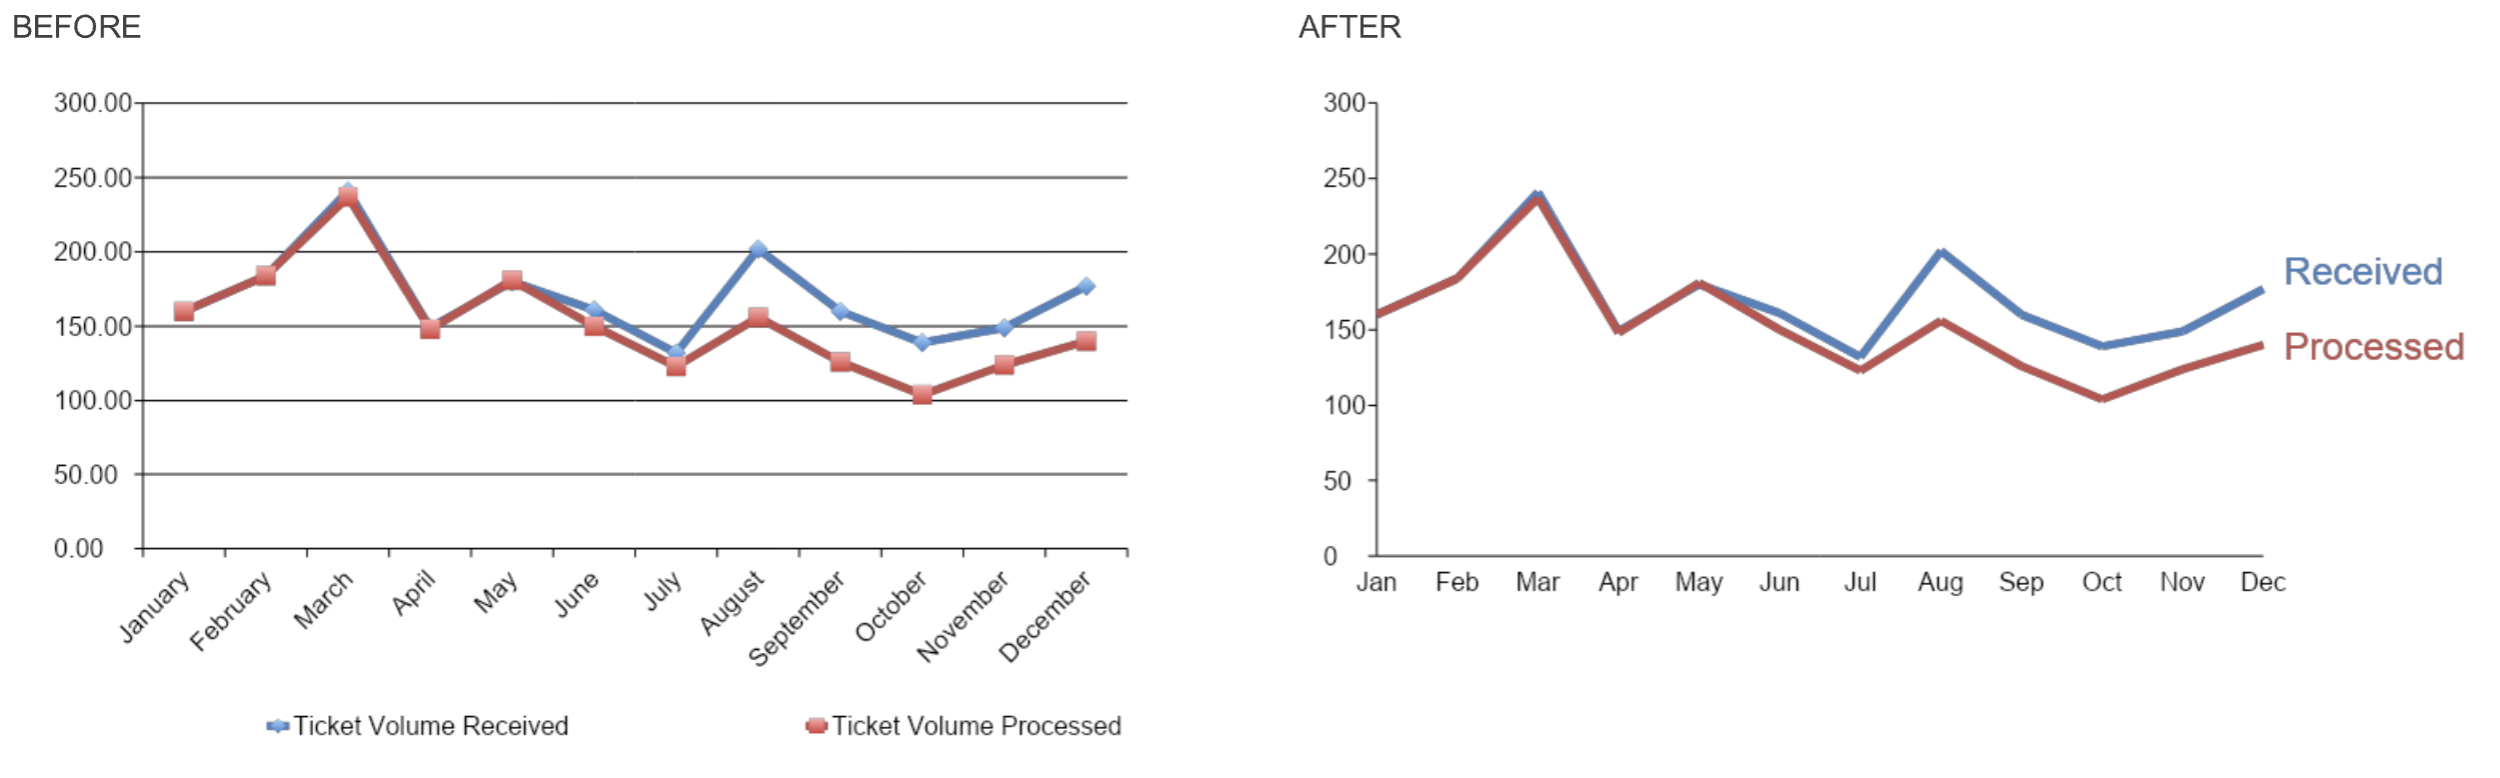 


## Design Principles - Part II: Line Charts

### Line charts imply continuity

> 💡 **A line chart physically connects every data point. That connection implies the thing between the points is real — that values are continuous, not discrete. The line says: this is a trend. So only use a line when it IS a trend**

| Use a line | Use a bar instead |
|---|---|
| Time series (months, years, days) | Comparing unordered categories |
| Continuous process | Discrete groups (regions, products) |
| Showing a trajectory | Showing a snapshot comparison |




*Line graph variants: single series, two series, multiple series (‼️the spaghetti risk‼️)*


> 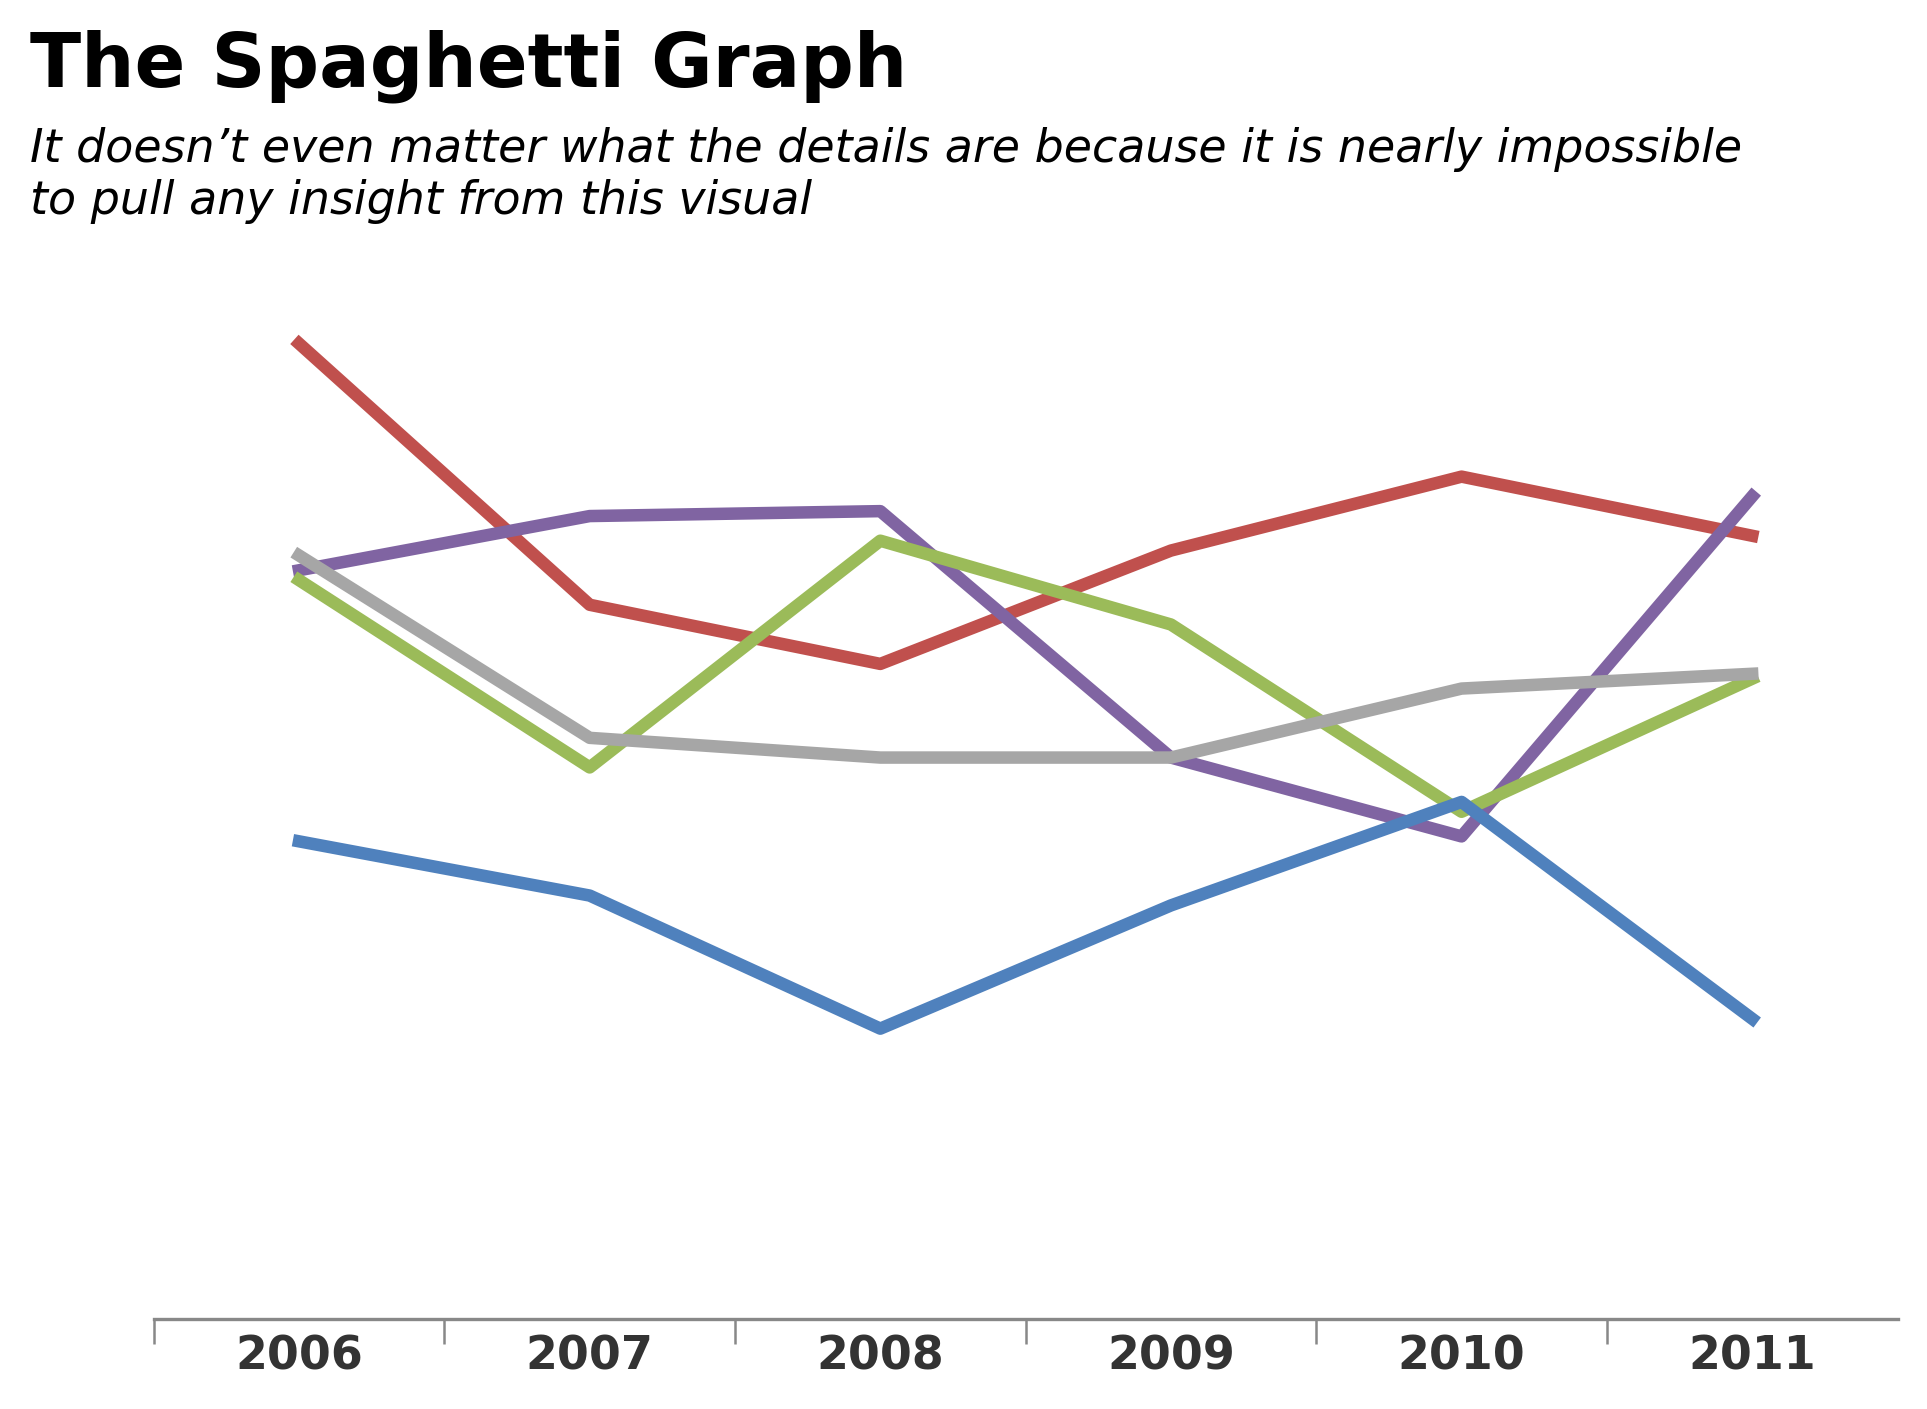



---
## Let's Code Some Examples 💻 


In [1]:
import pandas as pd
import plotly.express as px


df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


### Example 1 — Basic line chart: Clutter removal step by step

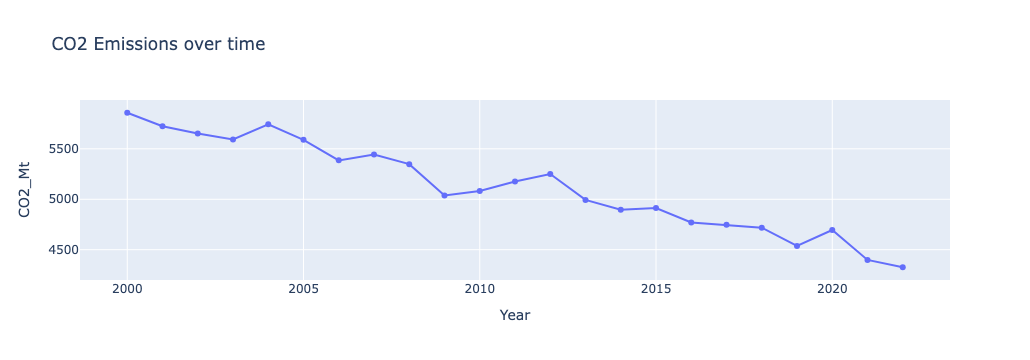

In [7]:

usa = df.loc[df['Country'] == 'United States']

fig = px.line(usa, x='Year', y='CO2_Mt', title='CO2 Emissions over time', markers=True)
fig.show()

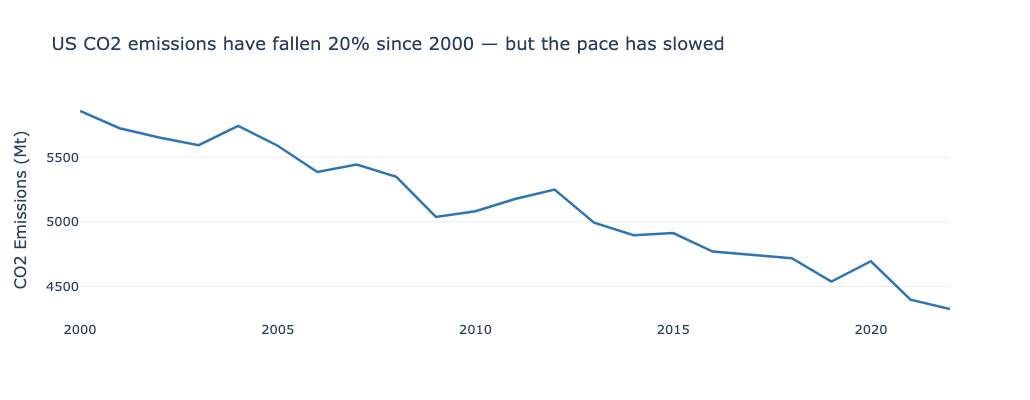

In [10]:
# Let's apply the principles

fig = px.line(usa, x='Year', y='CO2_Mt',
              labels={'CO2_Mt': 'CO2 Emissions (Mt)', 'Year': ''},
              color_discrete_sequence=['#2E75B6'],
              title='US CO2 emissions have fallen 20% since 2000 — but the pace has slowed',
              # Gestalt Closure: white background removes the need for a chart border
              template='plotly_white',
              # Gestalt Connection: no markers needed 
              markers=False,
              height=400)


fig.update_layout(
    font=dict(size=13),
    # Gestalt Continuity: make gridlines very light or remove completely so data stands out; don't compete with the line
    yaxis=dict(gridcolor='#EEEEEE', gridwidth=1),
    xaxis=dict(showgrid=False),
)

fig.update_traces(
    line=dict(width=2.5),   # slightly thicker line = more prominent than gridline
)


fig.show()


### Example 2 — Multi-series: the spaghetti problem and how to fix it

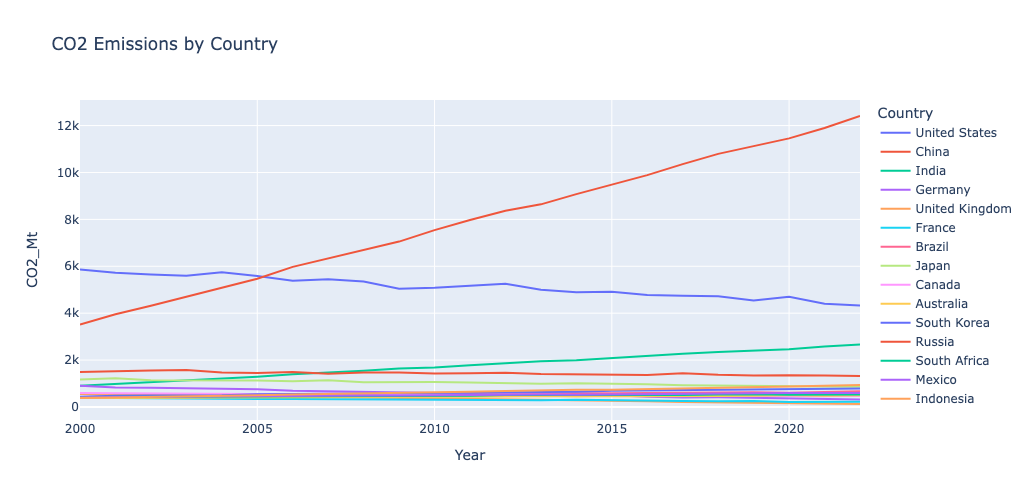

In [11]:

fig = px.line(df, x='Year', y='CO2_Mt', color='Country',
              title='CO2 Emissions by Country', height=500)

fig.show()

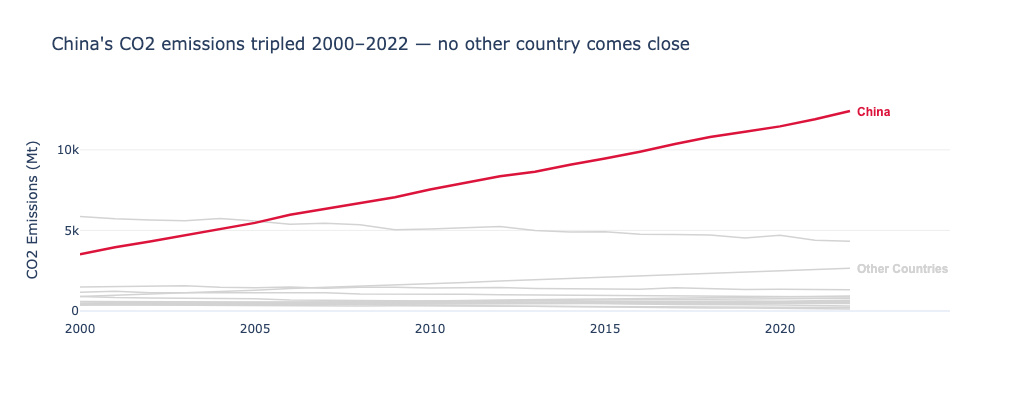

In [31]:
# Let's apply the principles

# Choose a country to highlight
highlight = 'China'

# Build colour map: highlight in red, everything else grey
color_map = {c: 'crimson' if c == highlight else 'lightgrey' for c in df['Country'].unique()}

fig = px.line(df, x='Year', y='CO2_Mt', color='Country',
              color_discrete_map=color_map,
              labels={'CO2_Mt': 'CO2 Emissions (Mt)', 'Year': ''},
              title="China's CO2 emissions tripled 2000–2022 — no other country comes close",
              template='plotly_white',
              height=400
              )

fig.update_traces(
    line=dict(width=1.5),   # default: thin for context countries
    showlegend=False      # direct label replaces legend (Gestalt proximity)
)

# Override highlighted country: thicker line to draw attention
fig.update_traces(
    line=dict(width=2.5),
    selector=dict(name=highlight) # each line is named after a country in the traces of the figure
)

# Direct label at end of highlighted line
highlight_label = df.loc[(df['Country'] == highlight) & (df['Year'] == df['Year'].max())]

others_label = df.loc[(df['Country'] == 'India') & (df['Year'] == df['Year'].max())]

# add highlight label
fig.add_annotation(
    x=highlight_label['Year'].values[0], y=highlight_label['CO2_Mt'].values[0],
    text=highlight, showarrow=False,
    xanchor='left', xshift=5,
    font=dict(color='crimson', size=12, weight='bold', family='Arial')
)

# add others label (optional)
fig.add_annotation(
    x=others_label['Year'].values[0], y=others_label['CO2_Mt'].values[0],
    text='Other Countries', showarrow=False,
    xanchor='left', xshift=5,
    font=dict(color='lightgrey', size=12, weight='bold', family='Arial')
)

fig.update_layout(
    title="China's CO2 emissions tripled 2000–2022 — no other country comes close",
    yaxis=dict(gridcolor='#EEEEEE'),
    xaxis=dict(showgrid=False)
)

fig.show()

---
## Class Exercise 💪 💻


**Remember:**
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title
